In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f_oneway, chi2_contingency

TITANIC_FILE = "data/Titanic-Dataset.csv"
AB_SESSIONS_FILE = "data/sessions_data.csv"
AB_USERS_FILE = "data/users_data.csv"

df_titanic = pd.read_csv(TITANIC_FILE)
df_sessions = pd.read_csv(AB_SESSIONS_FILE)
df_users = pd.read_csv(AB_USERS_FILE)

# Task 1

In [30]:
contingency_sex = pd.crosstab(df_titanic['Sex'], df_titanic['Survived'])
print(contingency_sex)

chi2_sex, p_sex, _, _ = chi2_contingency(contingency_sex)
print(f"χ^2 = {chi2_sex:.4f}, p-value = {p_sex:.6f}")

Survived    0    1
Sex               
female     81  233
male      468  109
χ^2 = 260.7170, p-value = 0.000000


In [31]:
df_titanic['Age_Group'] = np.where(df_titanic['Age'] <= 16, 'Child', 'Adult')
df_titanic['Age_Group'] = df_titanic['Age_Group'].fillna('Adult')

contingency_age = pd.crosstab(df_titanic['Age_Group'], df_titanic['Survived'])
print(contingency_age)

chi2_age, p_age, _, _ = chi2_contingency(contingency_age)
print(f"χ^2 = {chi2_age:.4f}, p-value = {p_age:.6f}")

Survived     0    1
Age_Group          
Adult      504  287
Child       45   55
χ^2 = 12.3703, p-value = 0.000436


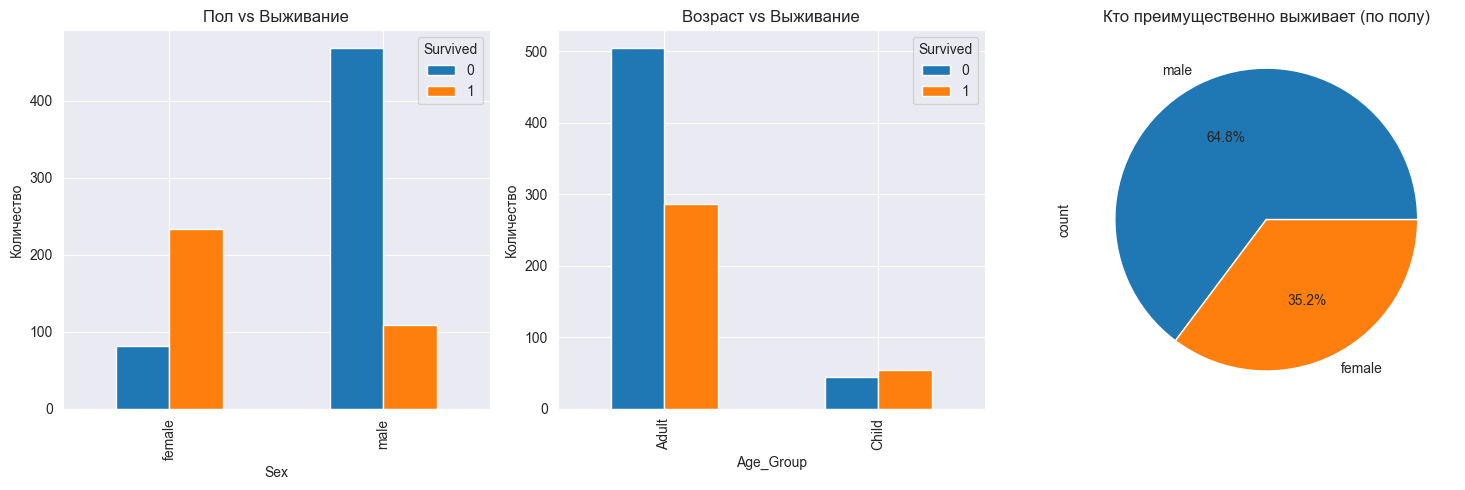

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

pd.crosstab(df_titanic['Sex'], df_titanic['Survived']).plot(kind='bar', ax=axes[0])
axes[0].set_title('Пол vs Выживание')
axes[0].set_ylabel('Количество')

pd.crosstab(df_titanic['Age_Group'], df_titanic['Survived']).plot(kind='bar', ax=axes[1])
axes[1].set_title('Возраст vs Выживание')
axes[1].set_ylabel('Количество')

df_titanic['Sex'].value_counts().plot(kind='pie', ax=axes[2], autopct='%1.1f%%')
axes[2].set_title('Кто преимущественно выживает (по полу)')

plt.tight_layout()
plt.show()

# Task * (короче второе которое)

In [33]:
df_ab = df_sessions.merge(df_users, on='user_id', how='left')
df_ab['booked'] = df_ab['booking_timestamp'].notna().astype(int)

control = df_ab[df_ab['experiment_group'] == 'control']['booked']
variant = df_ab[df_ab['experiment_group'] == 'variant']['booked']
f1, p1 = f_oneway(control, variant)
print(f"F = {f1:.4f}, p = {p1:.4f}")

F = 0.0750, p = 0.7841


In [34]:
time_control = df_ab[df_ab['experiment_group'] == 'control']['time_to_booking'].dropna()
time_variant = df_ab[df_ab['experiment_group'] == 'variant']['time_to_booking'].dropna()
f2, p2 = f_oneway(time_control, time_variant)
print(f"F = {f2:.4f}, p = {p2:.4f}")

F = 101.7728, p = 0.0000


In [35]:
from scipy.stats import mannwhitneyu

df_ab['hour'] = df_ab['session_start_timestamp'].str[:2].astype(float)
df_ab['day_night'] = np.where(df_ab['hour'].between(6, 21), 'Day', 'Night')

day = df_ab[df_ab['day_night'] == 'Day']['booked']
night = df_ab[df_ab['day_night'] == 'Night']['booked']

print(f"День: {len(day)} сессий")
print(f"Ночь: {len(night)} сессий")

if len(day) > 0 and len(night) > 0:
    stat, p3 = mannwhitneyu(day, night)
    print(f"U = {stat:.4f}, p = {p3:.4f}")
else:
    print("Одна из групп пуста — тест невозможен") # не, серьезно, а как задание то выполнить?.. в общем я сделал че смог: не мы такие - жизни такая

День: 16923 сессий
Ночь: 0 сессий
Одна из групп пуста — тест невозможен


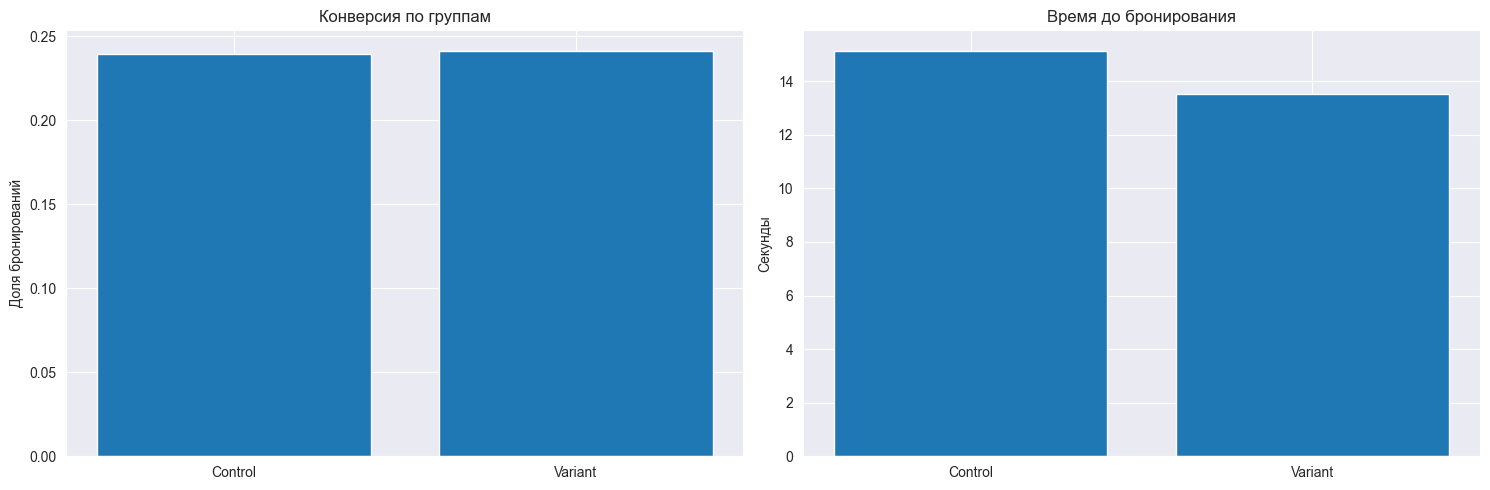

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(['Control', 'Variant'], [control.mean(), variant.mean()])
axes[0].set_title('Конверсия по группам')
axes[0].set_ylabel('Доля бронирований')

axes[1].bar(['Control', 'Variant'], [time_control.mean(), time_variant.mean()])
axes[1].set_title('Время до бронирования')
axes[1].set_ylabel('Секунды')

# день с ночью выводить смысла нет, тк ночных данных нет

plt.tight_layout()
plt.show()